# 10 · Precursor flux, my Fig. 3, and the other models in Dichiara's Table 2

Sprint tasks 4 and 5, building on the joint Band fit of `09_precursor_band_fit.ipynb`:

* turn the counts into flux: the 10–1000 keV energy flux (Dichiara: 3.324 ± 0.038 × 10⁻⁵ erg cm⁻² s⁻¹)
  and an unfolded νFν spectrum with residuals, my version of Dichiara Fig. 3;
* fit the other precursor models in Table 2: blackbody, Comptonized (cutoff power law) and
  Band + blackbody, and compare how well each one fits.

Same data, energy ranges and statistic as notebook 09 (C-stat with known background, NaI 8–900 keV,
BGO 200 keV–40 MeV).

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

from gdt.core.spectra.functions import Band, BlackBody, Comptonized

from settings import (CODE_DIR, BURST_ID, SPECTRAL_DETECTORS, FIT_RANGE_NAI,
                      FIT_RANGE_BGO, FLUX_RANGE, FIGURE_DIR)
from spectral_fit_tools import (load_spectra, channel_mask, fit_model, cstat,
                                covariance, flux_with_error)

SPECTRUM_DIR = CODE_DIR / "spectra"
phas, baks, rsps = load_spectra(SPECTRUM_DIR, BURST_ID, SPECTRAL_DETECTORS)
masks = [channel_mask(rsp, FIT_RANGE_BGO if det.startswith("b") else FIT_RANGE_NAI)
         for rsp, det in zip(rsps, SPECTRAL_DETECTORS)]

band = Band()
band_fit = fit_model(phas, baks, rsps, masks, band,
                     [[0.01, 500.0, -0.5, -2.5, 100.0], [1.5, 170.0, -0.6, -2.9, 100.0]])
with open(SPECTRUM_DIR / "precursor_band_fit.json") as f:
    saved = json.load(f)
print("Band:", np.round(band_fit.parameters, 4), f"C-stat {cstat(band_fit):.1f}/{band_fit.dof}")
print("same as notebook 09:", np.allclose(band_fit.parameters, list(saved["parameters"].values()), rtol=1e-3))

Band: [  1.6306 170.2679  -0.6332  -2.9534] C-stat 568.7/484
same as notebook 09: True


## Energy flux, 10–1000 keV

The flux is the model, not the data: ∫ E N(E) dE over 10–1000 keV for the best-fit Band
parameters. Its error comes from drawing 2000 parameter sets from the covariance matrix
(`spectral_fit_tools.covariance`; GDT's own gave ~5× smaller errors, see notebooks 09 and 11) and taking the spread
of the resulting fluxes. This is a mean flux over the 0.384 s window. Notebook 11 checks the error against the scatter of
1000 simulated fits (0.039 × 10⁻⁵): the Gaussian propagation is fine here.

In [2]:
flux, flux_err = flux_with_error(band, band_fit, FLUX_RANGE)
print(f"Band {FLUX_RANGE[0]:.0f}-{FLUX_RANGE[1]:.0f} keV energy flux: "
      f"({flux / 1e-5:.3f} +/- {flux_err / 1e-5:.3f}) x 1e-5 erg/cm2/s")
print("Dichiara:                         (3.324 +/- 0.038) x 1e-5 erg/cm2/s")
print(f"fluence over the window: {flux * 0.384:.2e} erg/cm2")

Band 10-1000 keV energy flux: (3.322 +/- 0.041) x 1e-5 erg/cm2/s
Dichiara:                         (3.324 +/- 0.038) x 1e-5 erg/cm2/s
fluence over the window: 1.28e-05 erg/cm2


## νFν spectrum with residuals (my Fig. 3)

A detector doesn't measure photon flux directly: the response smears each photon energy over many
channels. The usual way to plot data in flux units (and, as far as I can tell, how RMfit made Fig. 3) is to **unfold**
with the model: in each group of channels,

$$N_\mathrm{data}(E) = N_\mathrm{model}(E)\times\frac{\text{net counts}}{\text{model counts}},$$

so a point sits on the model curve exactly when the counts agree with the model. The plotted points
therefore depend on the model, so they are a way of *displaying* the fit, not a model-free measurement
of the photon spectrum. The residuals are (net − model counts) / σ with σ² = model + background + σ_B²
counts, the same definition as GDT's  (checked in notebook 11).
For display only, adjacent channels are grouped until each group has a net signal of at least 5σ
(at most 16 channels). The fit itself uses every channel.

νFν = E² N(E) is in keV² ph cm⁻² s⁻¹ keV⁻¹ (= keV cm⁻² s⁻¹), as in RMfit; its peak is E_peak.

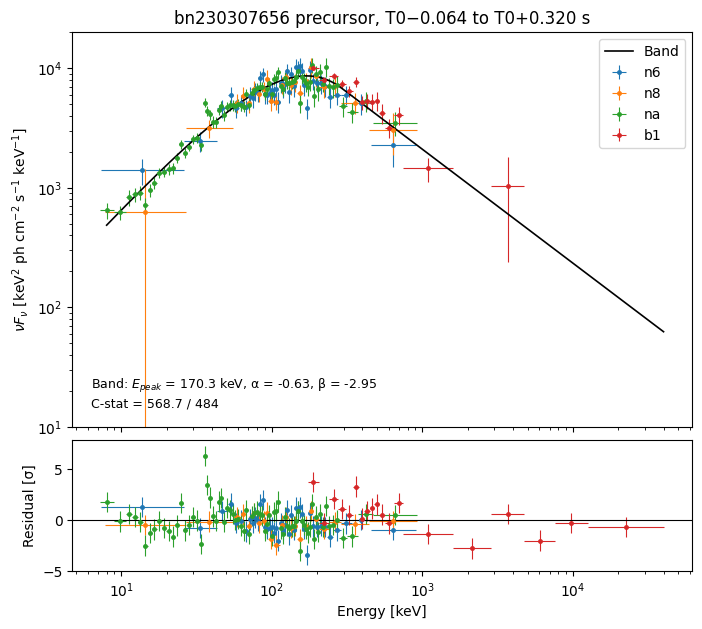

In [3]:
def group_channels(net, err, mask, min_sigma=5.0, max_channels=16):
    # Consecutive fitted channels -> groups with net/err >= min_sigma
    groups, current = [], []
    for ch in np.flatnonzero(mask):
        current.append(ch)
        n, e = net[current].sum(), np.sqrt(np.sum(err[current]**2))
        if n / e >= min_sigma or len(current) >= max_channels:
            groups.append(current)
            current = []
    if current:                       # leftover channels join the last group
        if groups:
            groups[-1].extend(current)
        else:
            groups.append(current)
    return groups

def unfolded_points(function, fitter, pha, bak, rsp, mask):
    params = fitter.parameters
    exposure = pha.exposure
    counts = np.asarray(pha.data.counts, dtype=float)
    bkg = np.asarray(bak.data.counts, dtype=float)
    bkg_err = np.asarray(bak.data.count_uncertainty, dtype=float)
    net, err = counts - bkg, np.sqrt(counts + bkg_err**2)    # data error, for the points
    model = np.asarray(rsp.drm.fold_spectrum(function.fit_eval, params)) * exposure
    lo, hi = np.asarray(rsp.ebounds.low_edges()), np.asarray(rsp.ebounds.high_edges())
    rows = []
    for g in group_channels(net, err, mask):
        e_lo, e_hi = lo[g[0]], hi[g[-1]]
        e_mid = np.sqrt(e_lo * e_hi)
        ratio = net[g].sum() / model[g].sum()
        ratio_err = np.sqrt(np.sum(err[g]**2)) / model[g].sum()
        nufnu = e_mid**2 * function.fit_eval(params, np.array([e_mid]))[0]
        rows.append((e_lo, e_mid, e_hi, nufnu * ratio, nufnu * ratio_err,
                     # residual in units of the model's sigma, as GDT's fitter.residuals()
                     (net[g].sum() - model[g].sum())
                     / np.sqrt(np.sum(model[g] + bkg[g] + bkg_err[g]**2))))
    return np.array(rows)

colours = {"n6": "tab:blue", "n8": "tab:orange", "na": "tab:green", "b1": "tab:red"}
fig, (ax, ax_res) = plt.subplots(2, 1, figsize=(8, 7), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05})
for det, pha, bak, rsp, mask in zip(SPECTRAL_DETECTORS, phas, baks, rsps, masks):
    p = unfolded_points(band, band_fit, pha, bak, rsp, mask)
    good = p[:, 3] > 0
    ax.errorbar(p[good, 1], p[good, 3], xerr=[p[good, 1] - p[good, 0], p[good, 2] - p[good, 1]],
                yerr=p[good, 4], fmt="o", ms=2.5, lw=0.8, color=colours[det], label=det)
    ax_res.errorbar(p[:, 1], p[:, 5], xerr=[p[:, 1] - p[:, 0], p[:, 2] - p[:, 1]], yerr=1.0,
                    fmt="o", ms=2.5, lw=0.8, color=colours[det])

energies = np.logspace(np.log10(FIT_RANGE_NAI[0]), np.log10(FIT_RANGE_BGO[1]), 400)
ax.plot(energies, energies**2 * band.fit_eval(band_fit.parameters, energies), color="black",
        lw=1.2, label="Band")
p = band_fit.parameters
ax.text(0.03, 0.05, f"Band: $E_{{peak}}$ = {p[1]:.1f} keV, α = {p[2]:.2f}, β = {p[3]:.2f}\n"
        f"C-stat = {cstat(band_fit):.1f} / {band_fit.dof}", transform=ax.transAxes, fontsize=9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(10, 2e4)
ax.set_ylabel(r"$\nu F_\nu$ [keV$^2$ ph cm$^{-2}$ s$^{-1}$ keV$^{-1}$]")
ax.set_title(f"{BURST_ID} precursor, T0−0.064 to T0+0.320 s")
ax.legend(loc="upper right")
ax_res.axhline(0, color="black", lw=0.8)
ax_res.set_ylabel("Residual [σ]")
ax_res.set_xlabel("Energy [keV]")
fig.savefig(FIGURE_DIR / "10_precursor_nufnu.png", dpi=200, bbox_inches="tight")
plt.show()

## The other models in Table 2

Starting values matter here too (the blackbody amplitude in particular spans orders of magnitude),
so each model is fitted from a few starts. In Band + BB the Band part starts at the Band best fit.
Errors are from the covariance matrix; for the Band fit they agree with the profile errors to a few
per cent (notebook 09).

In [4]:
models = {
    "Black Body": (BlackBody(), [[1e-3, 30.0], [3e-3, 36.0], [1e-2, 20.0]]),
    "Comptonized": (Comptonized(), [[1.0, 200.0, -0.8, 100.0], [0.5, 300.0, -1.0, 100.0]]),
    "Band": (band, None),
    "Band+BB": (Band() + BlackBody(), [[1.5, 200.0, -0.6, -3.2, 100.0, 3e-4, 15.0],
                                       [*band.default_values, 1e-4, 30.0],
                                       [1.0, 200.0, -0.6, -3.0, 100.0, 1e-3, 15.0]]),
}
dichiara = {  # flux (1e-5), Epeak, alpha, beta, kT, C-stat, dof
    "Black Body": (2.899, None, None, None, 36.0, 3527.3, 482),
    "Comptonized": (3.288, 198.7, -0.80, None, None, 606.1, 481),
    "Band": (3.324, 170.3, -0.63, -2.95, None, 563.1, 480),
    "Band+BB": (3.333, 203.9, -0.59, -3.20, 15.3, 536.1, 478),
}
results = {}
for name, (function, starts) in models.items():
    fitter = band_fit if starts is None else fit_model(phas, baks, rsps, masks, function, starts)
    names = [p[0] for p in function.param_list]
    free = [n for n, f in zip(names, function.free) if f]
    errors = np.sqrt(np.diag(covariance(fitter)))
    flux, flux_err = flux_with_error(function, fitter, FLUX_RANGE)
    results[name] = dict(fitter=fitter, function=function,
                         values={n: (v, e) for n, v, e in zip(free, fitter.parameters, errors)},
                         flux=(flux, flux_err), cstat=cstat(fitter), dof=fitter.dof)

def get(values, *keys):
    for k in keys:
        if k in values:
            return values[k]
    return None

def fmt(pair, digits):
    return "" if pair is None else f"{pair[0]:.{digits}f} ± {pair[1]:.{digits}f}"

header = f"{'model':12s}{'flux 1e-5':>16s}{'Epeak':>16s}{'alpha':>16s}{'beta':>16s}{'kT':>14s}{'C-stat/dof':>14s}"
print(header)
for name, r in results.items():
    v = r["values"]
    print(f"{name:12s}{fmt((r['flux'][0] / 1e-5, r['flux'][1] / 1e-5), 3):>16s}"
          f"{fmt(get(v, 'Epeak', 'Band: Epeak'), 1):>16s}"
          f"{fmt(get(v, 'alpha', 'index', 'Band: alpha'), 2):>16s}"
          f"{fmt(get(v, 'beta', 'Band: beta'), 2):>16s}"
          f"{fmt(get(v, 'kT', 'BlackBody: kT'), 1):>14s}"
          f"{r['cstat']:8.1f}/{r['dof']}")
    d = dichiara[name]
    cell = lambda x, digits: "" if x is None else f"{x:.{digits}f}"
    print(f"{'  Dichiara':12s}{cell(d[0], 3):>16s}{cell(d[1], 1):>16s}{cell(d[2], 2):>16s}"
          f"{cell(d[3], 2):>16s}{cell(d[4], 1):>14s}{d[5]:8.1f}/{d[6]}")

/home/ignaciobl2004/miniforge3/envs/MVTEnv/lib/python3.13/site-packages/gdt/core/spectra/functions.py:926: RuntimeWarning: overflow encountered in exp
  fxn = A * x ** 2 / (np.exp(x / kT) - 1.0)


/home/ignaciobl2004/miniforge3/envs/MVTEnv/lib/python3.13/site-packages/gdt/core/spectra/functions.py:926: RuntimeWarning: overflow encountered in exp
  fxn = A * x ** 2 / (np.exp(x / kT) - 1.0)


model              flux 1e-5           Epeak           alpha            beta            kT    C-stat/dof
Black Body     2.896 ± 0.032                                                    36.0 ± 0.3  3532.4/486
  Dichiara             2.899                                                          36.0  3527.3/482
Comptonized    3.286 ± 0.038     198.7 ± 3.8    -0.80 ± 0.03                                 612.0/485
  Dichiara             3.288           198.7           -0.80                                 606.1/481
Band           3.322 ± 0.041     170.3 ± 5.3    -0.63 ± 0.04    -2.95 ± 0.09                 568.7/484
  Dichiara             3.324           170.3           -0.63           -2.95                 563.1/480
Band+BB        3.331 ± 0.075    203.5 ± 10.5    -0.58 ± 0.10    -3.20 ± 0.17    15.2 ± 1.6   541.8/482
  Dichiara             3.333           203.9           -0.59           -3.20          15.3   536.1/478


### How well does each model fit?

Differences in C-stat between nested models (Comptonized ⊂ Band ⊂ Band + BB) are approximately χ²
distributed with as many d.o.f. as extra parameters (Wilks' theorem), so ΔC-stat measures how much
each extra parameter buys. BIC = C-stat + k ln n (k free parameters, n channels) penalises extra
parameters; a ΔBIC above ~10 is usually read as strong evidence.

In [5]:
n_channels = sum(m.sum() for m in masks)
print(f"{'model':12s}{'k':>3s}{'C-stat':>9s}{'ΔC vs Band':>12s}{'ΔBIC vs Band':>14s}{'Dichiara ΔC':>13s}")
for name, r in results.items():
    k = len(r["values"])
    bic = r["cstat"] + k * np.log(n_channels)
    bic_band = results["Band"]["cstat"] + 4 * np.log(n_channels)
    print(f"{name:12s}{k:3d}{r['cstat']:9.1f}{r['cstat'] - results['Band']['cstat']:12.1f}"
          f"{bic - bic_band:14.1f}{dichiara[name][5] - dichiara['Band'][5]:13.1f}")

model         k   C-stat  ΔC vs Band  ΔBIC vs Band  Dichiara ΔC
Black Body    2   3532.4      2963.7        2951.4       2964.2
Comptonized   3    612.0        43.3          37.2         43.0
Band          4    568.7         0.0           0.0          0.0
Band+BB       6    541.8       -26.9         -14.5        -27.0


* **Blackbody alone** is ruled out (ΔC ≈ +2960): the spectrum is far broader than a single
  temperature.
* **Comptonized → Band**: one extra parameter (β) improves the C-stat by ~43, so the precursor
  needs a high-energy power-law tail above the cutoff. This is why Dichiara pick Band.
* **Band → Band + BB**: two extra parameters improve the C-stat by ~27, the same as Dichiara's 27.0.
  Dichiara call this "not significant enough to justify the thermal component".
  * *Statistically* it is significant. Because a BB amplitude of zero sits on the edge of the allowed
    range, Wilks' theorem can't be relied on, so notebook 11 simulates 1000 Band-only spectra and fits
    both models to each: none reaches ΔC = 26.9 (the largest is 18.0), so p < 0.001. ΔBIC ≈ −14
    points the same way.
  * So a reason to dismiss the BB has to be *systematic*, not statistical, and there is a candidate:
    with kT ≈ 15 keV most of the BB's emission falls at ~20–80 keV (its νFν peaks at ~3.9 kT ≈
    60 keV), where n6 and n8 have little or no effective area and the NaI iodine K-edge (33.2 keV)
    sits. na's two largest residuals from the Band fit are +6.3σ (35.0–36.6 keV) and +3.4σ
    (36.6–38.2 keV), just above the K-edge. A small response error there could be what the BB is
    fitting. The simulations assume a perfect response, so they can't test this.
  * Notebook 11 tests this by removing na's 30–40 keV channels: the Band C-stat drops by ~56 for 7
    channels (so Band fits them badly), and the BB improvement falls from ~27 to ~17. The K-edge
    region explains part of the BB signal, not all of it. Worth asking David.

Below: νFν of each model at its best fit, to see where they differ.

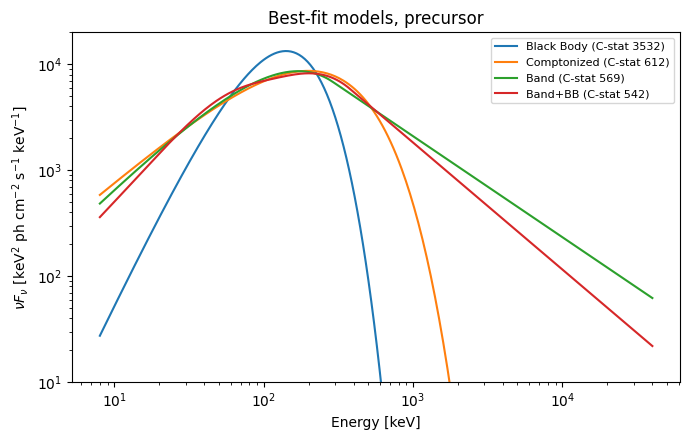

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, r in results.items():
    f = r["function"]
    ax.plot(energies, energies**2 * f.fit_eval(r["fitter"].parameters, energies),
            label=f"{name} (C-stat {r['cstat']:.0f})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(10, 2e4)
ax.set_xlabel("Energy [keV]")
ax.set_ylabel(r"$\nu F_\nu$ [keV$^2$ ph cm$^{-2}$ s$^{-1}$ keV$^{-1}$]")
ax.set_title("Best-fit models, precursor")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "10_precursor_models.png", dpi=200)
plt.show()